# Titanic Dataset: Exploratory Data Analysis (EDA)

## Project overview
This notebook explores passenger information from the Titanic dataset. It includes dataset inspection, summary tables for numerical and categorical columns, an age-distribution histogram, a gender-based survival-rate bar chart, and a correlation heatmap.

## Objectives
1. Load the supplied Titanic CSV file and prepare a clean analysis dataset.
2. Generate summary statistics for numerical and categorical columns.
3. Visualize passenger age distribution.
4. Compare survival rates by gender.
5. Explore correlations among numerical variables.
6. Record a short conclusion after each visualization.

**Dataset:** `titanic.csv` (891 rows and 12 columns in the supplied file).

In [1]:
# Import the libraries used in this analysis
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from pathlib import Path

sns.set_theme(style="whitegrid", palette="Set2")
pd.set_option("display.max_columns", None)
pd.set_option("display.float_format", lambda value: f"{value:,.2f}")

# Load the CSV file from the same folder as this notebook
data_path = Path("titanic.csv")
df_raw = pd.read_csv(data_path)

print(f"Dataset shape: {df_raw.shape[0]} rows × {df_raw.shape[1]} columns")
display(df_raw.head())

Dataset shape: 891 rows × 12 columns


,PassengerId,Survived,Pclass,Name,Sex,Age,SibSp,Parch,Ticket,Fare,Cabin,Embarked
0,1,0,3,"Braund, Mr. Owen Harris",male,22.00,1,0,A/5 21171,7.25,NaN,S
1,2,1,1,"Cumings, Mrs. John Bradley (Florence Briggs Th...",female,38.00,1,0,PC 17599,71.28,C85,C
2,3,1,3,"Heikkinen, Miss. Laina",female,26.00,0,0,STON/O2. 3101282,7.92,NaN,S
3,4,1,1,"Futrelle, Mrs. Jacques Heath (Lily May Peel)",female,35.00,1,0,113803,53.10,C123,S
4,5,0,3,"Allen, Mr. William Henry",male,35.00,0,0,373450,8.05,NaN,S


## 1. Inspect and clean the data

The supplied CSV contains missing values in `Age`, `Cabin`, and `Embarked`. To make the analysis dataset more complete:

- Fill missing `Age` values with the median age.
- Fill missing `Embarked` values with the most frequent port.
- Fill missing `Cabin` values with the label `Unknown`.
- Remove duplicate rows, if any.

The original file remains unchanged. The cleaned dataset is saved as `titanic_cleaned.csv`.

In [2]:
# Inspect column types and missing values before cleaning
display(df_raw.info())
display(df_raw.isnull().sum().to_frame(name="Missing values"))

# Work on a copy so the original data is preserved
df = df_raw.copy()

# Remove duplicate rows
df = df.drop_duplicates()

# Fill missing values
if "Age" in df.columns:
    df["Age"] = df["Age"].fillna(df["Age"].median())

if "Embarked" in df.columns:
    df["Embarked"] = df["Embarked"].fillna(df["Embarked"].mode()[0])

if "Cabin" in df.columns:
    df["Cabin"] = df["Cabin"].fillna("Unknown")

# Save the cleaned data for reuse
df.to_csv("titanic_cleaned.csv", index=False)

print("Cleaned dataset shape:", df.shape)
print("\nMissing values after cleaning:")
display(df.isnull().sum().to_frame(name="Missing values"))

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 891 entries, 0 to 890
Data columns (total 12 columns):
 #   Column       Non-Null Count  Dtype  
---  ------       --------------  -----  
 0   PassengerId  891 non-null    int64  
 1   Survived     891 non-null    int64  
 2   Pclass       891 non-null    int64  
 3   Name         891 non-null    object 
 4   Sex          891 non-null    object 
 5   Age          714 non-null    float64
 6   SibSp        891 non-null    int64  
 7   Parch        891 non-null    int64  
 8   Ticket       891 non-null    object 
 9   Fare         891 non-null    float64
 10  Cabin        204 non-null    object 
 11  Embarked     889 non-null    object 
dtypes: float64(2), int64(5), object(5)
memory usage: 83.7+ KB


None

,Missing values
PassengerId,0
Survived,0
Pclass,0
Name,0
Sex,0
Age,177
SibSp,0
Parch,0
Ticket,0
Fare,0


Cleaned dataset shape: (891, 12)

Missing values after cleaning:


,Missing values
PassengerId,0
Survived,0
Pclass,0
Name,0
Sex,0
Age,0
SibSp,0
Parch,0
Ticket,0
Fare,0


## 2. Summary statistics

The numerical summary reports count, mean, standard deviation, minimum, quartiles, and maximum. The categorical summary reports count, number of unique values, most frequent value, and its frequency.

In [3]:
# Summary table for numerical columns
numeric_summary = df.select_dtypes(include="number").describe().T
display(numeric_summary)

,count,mean,std,min,25%,50%,75%,max
PassengerId,891.00,446.00,257.35,1.00,223.50,446.00,668.50,891.00
Survived,891.00,0.38,0.49,0.00,0.00,0.00,1.00,1.00
Pclass,891.00,2.31,0.84,1.00,2.00,3.00,3.00,3.00
Age,891.00,29.36,13.02,0.42,22.00,28.00,35.00,80.00
SibSp,891.00,0.52,1.10,0.00,0.00,0.00,1.00,8.00
Parch,891.00,0.38,0.81,0.00,0.00,0.00,0.00,6.00
Fare,891.00,32.20,49.69,0.00,7.91,14.45,31.00,512.33


In [4]:
# Summary table for categorical columns
categorical_summary = df.select_dtypes(include=["object", "category"]).describe().T
display(categorical_summary)

,count,unique,top,freq
Name,891,891,"Braund, Mr. Owen Harris",1
Sex,891,2,male,577
Ticket,891,681,1601,7
Cabin,891,148,Unknown,687
Embarked,891,3,S,646


## 3. Age distribution

The histogram shows how passenger ages are distributed. The median-imputed values are included, so the chart uses the cleaned `Age` column.

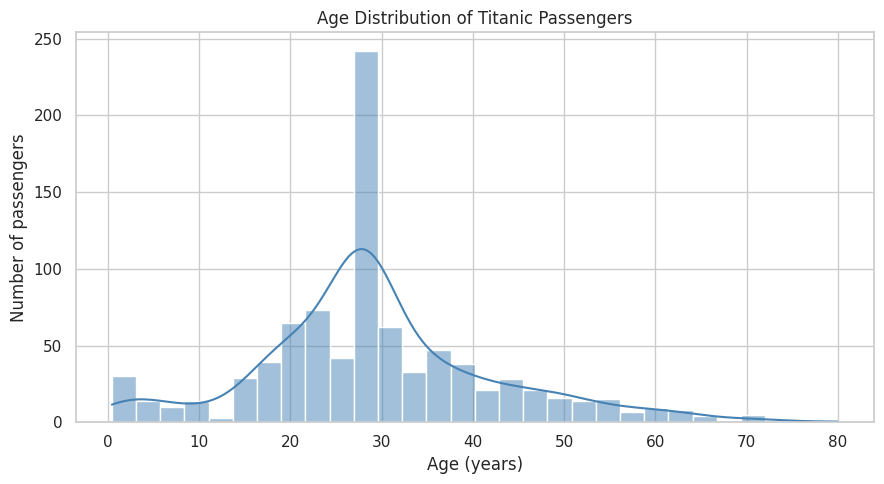

In [5]:
plt.figure(figsize=(9, 5))
sns.histplot(data=df, x="Age", bins=30, kde=True, color="steelblue")
plt.title("Age Distribution of Titanic Passengers")
plt.xlabel("Age (years)")
plt.ylabel("Number of passengers")
plt.tight_layout()
plt.show()

### Conclusion: Age distribution

The histogram shows the spread of passenger ages and highlights the age ranges with the most passengers. The dataset contains passengers across a broad range of ages, with fewer passengers at the oldest ages. Missing ages were filled using the median, so the imputed values contribute to the distribution.

## 4. Survival rate by gender

`Survived` is coded as 0 for did not survive and 1 for survived. Therefore, the mean of `Survived` within each gender gives the survival proportion.

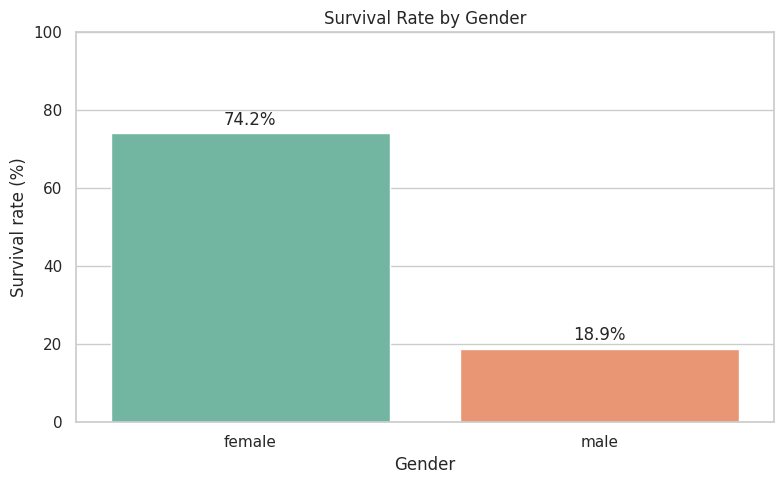

,Sex,Survival rate (%)
0,female,74.20
1,male,18.89


In [6]:
gender_survival = (
    df.groupby("Sex", observed=False)["Survived"]
      .mean()
      .mul(100)
      .reset_index(name="Survival rate (%)")
)

plt.figure(figsize=(8, 5))
ax = sns.barplot(
    data=gender_survival,
    x="Sex",
    y="Survival rate (%)",
    hue="Sex",
    legend=False
)
plt.title("Survival Rate by Gender")
plt.xlabel("Gender")
plt.ylabel("Survival rate (%)")
plt.ylim(0, 100)

for container in ax.containers:
    ax.bar_label(container, fmt="%.1f%%", padding=3)

plt.tight_layout()
plt.show()

display(gender_survival)

### Conclusion: Survival rate by gender

The bar chart compares the percentage of passengers who survived in each gender group. In this dataset, female passengers had a substantially higher survival rate than male passengers. This is an association in the observed data and does not, by itself, establish causation.

## 5. Correlation heatmap

The heatmap uses Pearson correlation for numerical columns. `PassengerId` is excluded because it is an identifier rather than a meaningful passenger measurement. Correlation values range from -1 to +1.

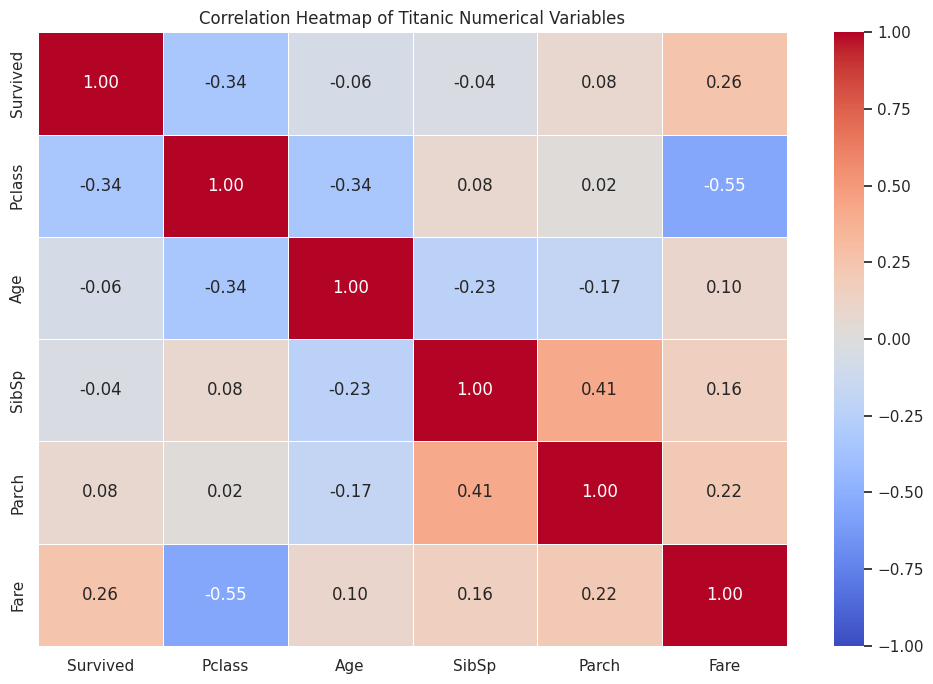

,Survived,Pclass,Age,SibSp,Parch,Fare
Survived,1.00,-0.34,-0.06,-0.04,0.08,0.26
Pclass,-0.34,1.00,-0.34,0.08,0.02,-0.55
Age,-0.06,-0.34,1.00,-0.23,-0.17,0.10
SibSp,-0.04,0.08,-0.23,1.00,0.41,0.16
Parch,0.08,0.02,-0.17,0.41,1.00,0.22
Fare,0.26,-0.55,0.10,0.16,0.22,1.00


In [7]:
# Select numeric columns and exclude the passenger identifier
numeric_data = df.select_dtypes(include="number").drop(
    columns=["PassengerId"], errors="ignore"
)
correlation_matrix = numeric_data.corr()

plt.figure(figsize=(10, 7))
sns.heatmap(
    correlation_matrix,
    annot=True,
    cmap="coolwarm",
    center=0,
    vmin=-1,
    vmax=1,
    fmt=".2f",
    linewidths=0.5
)
plt.title("Correlation Heatmap of Titanic Numerical Variables")
plt.tight_layout()
plt.show()

display(correlation_matrix)

### Conclusion: Correlation heatmap

The heatmap summarizes the direction and strength of linear relationships between numerical variables. Passenger class (`Pclass`) is generally negatively correlated with fare (`Fare`), because lower class numbers represent higher passenger classes and tend to have higher fares. The heatmap also helps identify numerical variables associated with survival. Correlation does not imply causation, and categorical variables such as gender are not represented in this numerical-only heatmap.

## 6. Overall conclusion

This EDA examined the Titanic passenger dataset using summary statistics and visualizations. The age histogram described the passenger age distribution, the gender survival chart showed a clear difference in observed survival rates, and the correlation heatmap summarized relationships among numerical variables.

The analysis also identified and handled missing values before producing the visualizations. These findings describe patterns in the supplied dataset and should not be interpreted as proof of cause and effect.